# Task 4: Netflix Trend Prediction Analysis

## 1. Project Overview

### 1.1 Background

The growth and composition of a streaming platform's content library can provide useful insights into the types of content represented in its catalog and how those patterns have changed over time. Analyzing historical release-year distributions can help identify periods of increased content production, changes in the mix of movies and television shows, and broader patterns in the titles available on the platform.

This project examines release-year data from a Netflix titles dataset to identify historical content trends and explore whether these patterns can be used to forecast future values.

### 1.2 Problem Statement

Understanding historical content patterns is an important part of exploratory data analysis and predictive analytics. However, simply counting titles or plotting yearly distributions does not reveal whether observed patterns are consistent, how they differ between content types, or how they might evolve over time.

This analysis will aggregate titles by release year, investigate historical trends, develop forecasting models, and evaluate their performance on held-out observations. The results will be used to assess the usefulness and limitations of forecasting based on the available data.

### 1.3 Project Objectives

The main objectives are to:

1. Prepare and validate the release-year data for time series analysis.
2. Examine annual title counts and identify historical trends.
3. Compare release-year patterns for movies and TV shows.
4. Develop and evaluate suitable forecasting models.
5. Visualize forecasts alongside historical observations.
6. Interpret the findings and identify limitations affecting forecast reliability.

### 1.4 Business Value

The analysis demonstrates how historical data can be transformed into trend indicators and forecasts that support exploratory planning and decision-making. The findings may help stakeholders understand changes in the composition of a content catalog and explore potential future patterns.

However, the dataset represents titles available in the observed catalog rather than a complete historical record of Netflix's annual acquisitions or future content strategy. Forecasts must therefore be interpreted within the limits of the available data.

### 1.5 Scope

The analysis uses the `release_year` and `type` columns from the Netflix titles dataset. The primary analysis focuses on annual title counts, with separate analyses for movies and TV shows where appropriate.

The forecasting stage will use chronological training and testing periods to evaluate how well models predict unseen historical observations. Forecasts will be presented as estimates based on historical patterns, not as confirmed predictions of Netflix's future content decisions.


In [28]:
# Importing the required libraries

# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent styling for plots throughout the notebook
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Display all columns when inspecting DataFrames
pd.set_option("display.max_columns", None)

# Import tools for classification and evaluation.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
# Load the cleaned Netflix dataset prepared during the earlier analysis.
df = pd.read_csv("netflix_cleaned.csv")

display(df.head())

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,date_added_year,date_added_month,date_added_day,duration_value,duration_unit,genre_count
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,25,90,min,1
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,24,1,Season,3
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,24,1,Season,3
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,22,91,min,2
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,24,125,min,3


### 2. Inspecting Release Years

The release_year variable records the year each title was originally released. We will use it as the time dimension for examining historical content patterns.

Before aggregation, we need to check its data type, missing values, range, and distribution. These checks help determine whether the data is ready for time series analysis and whether any records need special handling.

In [3]:
# Check release-year data quality and historical coverage.
print("Release-year data type:", df["release_year"].dtype)

print("\nMissing release years:")
print(df["release_year"].isna().sum())

print("\nEarliest release year:", df["release_year"].min())
print("Latest release year:", df["release_year"].max())

print("\nNumber of distinct release years:")
print(df["release_year"].nunique())

# Preview the relevant fields.
display(df[["title", "type", "release_year"]].head(10))

Release-year data type: int64

Missing release years:
0

Earliest release year: 1925
Latest release year: 2021

Number of distinct release years:
74


,title,type,release_year
0,Dick Johnson Is Dead,Movie,2020
1,Ganglands,TV Show,2021
2,Midnight Mass,TV Show,2021
3,Confessions of an Invisible Girl,Movie,2021
4,Sankofa,Movie,1993
5,The Great British Baking Show,TV Show,2021
6,The Starling,Movie,2021
7,Motu Patlu in the Game of Zones,Movie,2019
8,Je Suis Karl,Movie,2021
9,Motu Patlu in Wonderland,Movie,2013


### 3. Distribution of Titles by Release Year

Examining the number of titles associated with each release year provides an initial view of the dataset's historical distribution. It can reveal periods with relatively few or many titles and help identify patterns that warrant further investigation.

We will first calculate the number of titles for each year, then visualize the complete distribution in the exploratory analysis section.

In [4]:
# Count titles by release year and arrange them chronologically.
release_year_counts = (
    df["release_year"]
    .value_counts()
    .sort_index()
)

print("Number of distinct release years:", len(release_year_counts))

print("\nMost recent 15 release years in the dataset:")
display(release_year_counts.tail(15).to_frame(name="title_count"))

Number of distinct release years: 74

Most recent 15 release years in the dataset:


,title_count
release_year,
2007,88
2008,135
2009,152
2010,192
2011,185
2012,236
2013,286
2014,352
2015,555


## 4. Preparing the Time Series

### 4.1 Aggregating Titles by Release Year

Time series analysis requires observations arranged in chronological order. In this project, each observation will represent the number of titles in the dataset associated with a particular release year.

We will aggregate the dataset into annual title counts and create a continuous yearly index for analysis. Years without any titles in the dataset will be represented with a count of zero, ensuring that each time interval is accounted for.

This preparation provides a consistent foundation for visualizing historical patterns and comparing forecasting models.



In [5]:
# Aggregate the number of titles released in each year.
yearly_counts = (
    df.groupby("release_year")
    .size()
    .sort_index()
)

# Create a continuous index covering the full release-year range.
full_year_range = pd.RangeIndex(
    start=int(yearly_counts.index.min()),
    stop=int(yearly_counts.index.max()) + 1,
    name="release_year"
)

# Include years with no titles as zero-count observations.
yearly_counts = yearly_counts.reindex(
    full_year_range,
    fill_value=0
)

# Convert the series into a DataFrame for easier analysis.
yearly_trends = yearly_counts.rename("title_count").reset_index()

print("Prepared time series shape:", yearly_trends.shape)
print("\nYear range:", yearly_trends["release_year"].min(),
      "to", yearly_trends["release_year"].max())
print("Number of annual observations:", len(yearly_trends))
print("Years with zero titles:", (yearly_trends["title_count"] == 0).sum())

display(yearly_trends.head())

Prepared time series shape: (97, 2)

Year range: 1925 to 2021
Number of annual observations: 97
Years with zero titles: 23


,release_year,title_count
0,1925,1
1,1926,0
2,1927,0
3,1928,0
4,1929,0


### 4.2 Visualizing Annual Release-Year Trends

A time series plot helps reveal long-term changes, periods of rapid growth, peaks, and declines that may not be obvious from a table.

The visualization will show annual title counts across the dataset's full release-year range to help us assess the overall shape of the series and determine whether recent observations differ from those in earlier years.

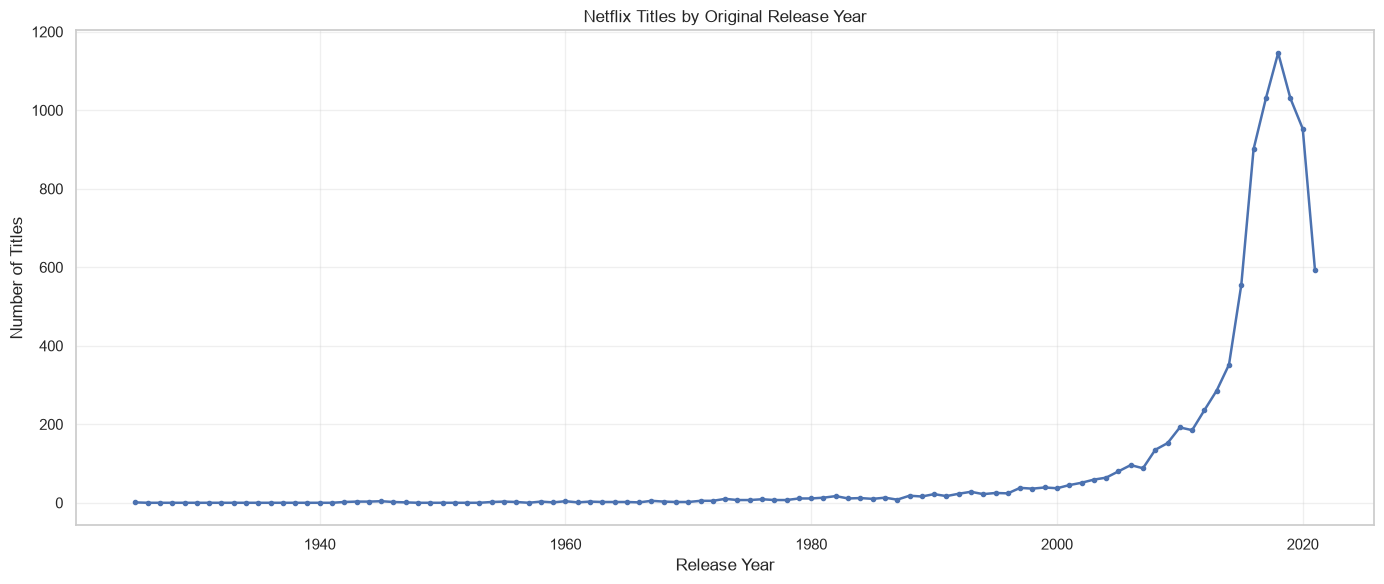

In [6]:
# Plot annual title counts to inspect historical patterns.
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_trends["release_year"],
    yearly_trends["title_count"],
    marker="o",
    markersize=3,
    linewidth=1.8
)

plt.title("Netflix Titles by Original Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4.3 Comparing Movies and TV Shows

Movies and TV shows may have different release-year distributions. Analyzing them separately can reveal whether the overall pattern is driven primarily by one content type.

We will count movies and TV shows by release year and visualize both series on the same chart. This comparison will provide additional context before selecting a forecasting approach.


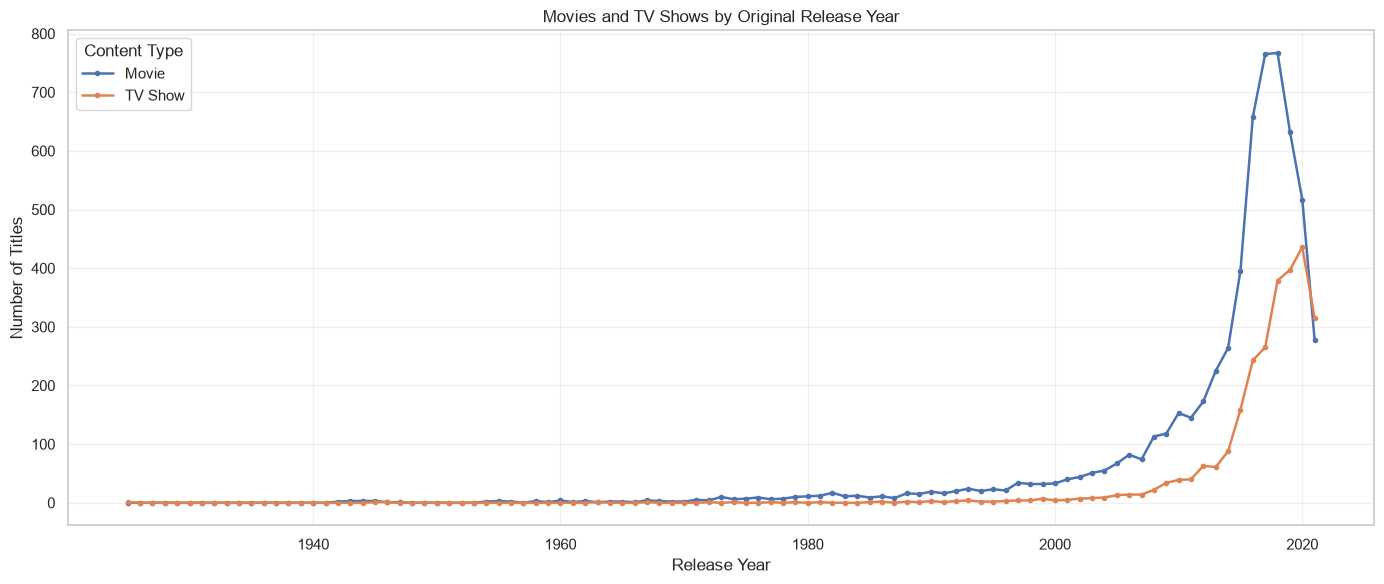

In [7]:
# Count titles separately for movies and TV shows by release year.
type_yearly_counts = (
    df.groupby(["release_year", "type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Ensure both content types use the same continuous year index.
type_yearly_counts = type_yearly_counts.reindex(
    full_year_range,
    fill_value=0
)

# Plot the two content types for comparison.
plt.figure(figsize=(14, 6))

for content_type in type_yearly_counts.columns:
    plt.plot(
        type_yearly_counts.index,
        type_yearly_counts[content_type],
        marker="o",
        markersize=3,
        linewidth=1.8,
        label=content_type
    )

plt.title("Movies and TV Shows by Original Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Count titles per release year and include any missing years.
yearly_counts = df.groupby("release_year").size().sort_index()

full_year_range = pd.RangeIndex(
    int(yearly_counts.index.min()),
    int(yearly_counts.index.max()) + 1,
    name="release_year"
)

yearly_counts = yearly_counts.reindex(full_year_range, fill_value=0)

# Create a DataFrame for subsequent analysis.
yearly_trends = yearly_counts.rename("title_count").reset_index()

print("Annual observations:", len(yearly_trends))
print("Years with zero titles:", (yearly_trends["title_count"] == 0).sum())

display(yearly_trends.head(10))

Annual observations: 97
Years with zero titles: 23


,release_year,title_count
0,1925,1
1,1926,0
2,1927,0
3,1928,0
4,1929,0
5,1930,0
6,1931,0
7,1932,0
8,1933,0
9,1934,0


In [13]:
# Share the annual counts behind the charts.
display(yearly_trends.tail(20))

# Compare Movies and TV Shows over the most recent years.
display(type_yearly_counts.tail(15))

,release_year,title_count
77,2002,51
78,2003,59
79,2004,64
80,2005,80
81,2006,96
82,2007,88
83,2008,135
84,2009,152
85,2010,192
86,2011,185


type,Movie,TV Show
release_year,,
2007,74,14
2008,113,22
2009,118,34
2010,153,39
2011,145,40
2012,173,63
2013,225,61
2014,264,88
2015,396,159


#### Key Findings

The dataset shows substantial growth in titles by original release year from 2015, reaching a peak in 2018 before declining through 2021. Movies dominate much of the period, while TV Shows become more prominent in the later years and outnumber Movies in 2020 and 2021. These patterns describe the release-year distribution of titles in the available dataset, rather than Netflix's annual content additions or total catalog growth.


### 5.**Building Forecasting Models**
We will aggregate titles by the year they were added to Netflix. This creates a yearly time series for exploring historical catalog additions and testing forecasting methods.

In [15]:
# Convert the addition year to numeric values for reliable aggregation.
df["date_added_year"] = pd.to_numeric(
    df["date_added_year"], errors="coerce"
)


In [16]:
# Count titles added in each year, excluding records without a valid year.
additions_by_year = (
    df.dropna(subset=["date_added_year"])
      .groupby("date_added_year")
      .size()
      .sort_index()
      .rename("titles_added")
      .reset_index()
)

additions_by_year["date_added_year"] = (
    additions_by_year["date_added_year"].astype(int)
)

display(additions_by_year)

,date_added_year,titles_added
0,2008,2
1,2009,2
2,2010,1
3,2011,13
4,2012,3
5,2013,11
6,2014,24
7,2015,82
8,2016,426
9,2017,1185


### 5.2 Historical Content-Addition Trends

Visualizing yearly additions helps identify growth periods, peaks, and declines before selecting forecasting models.


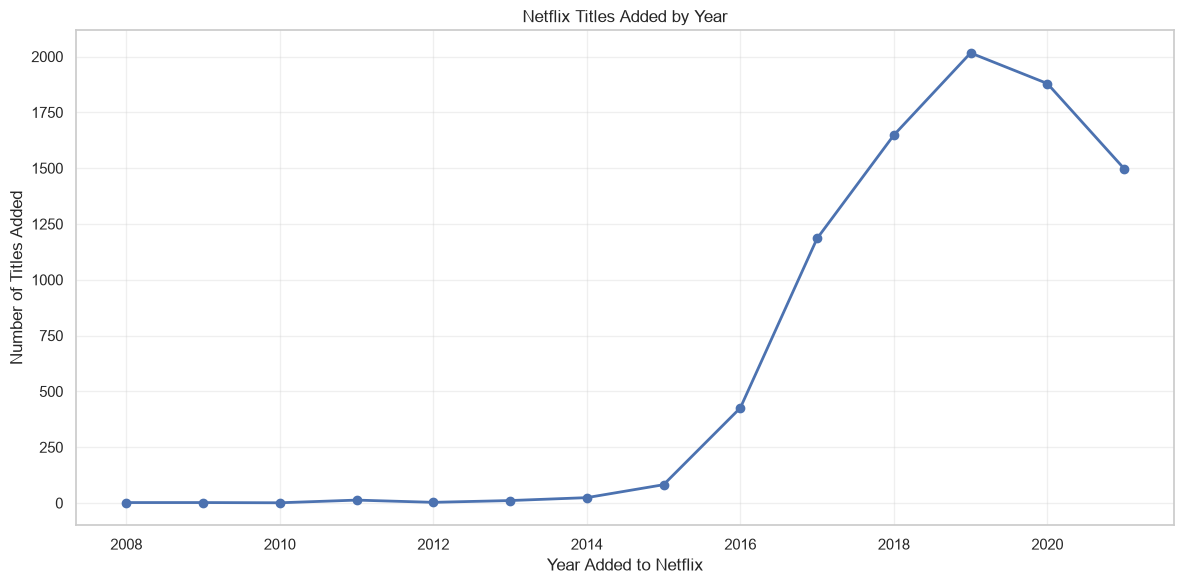

In [17]:
# Plot the number of titles added to Netflix each year.
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    additions_by_year["date_added_year"],
    additions_by_year["titles_added"],
    marker="o",
    linewidth=2
)

ax.set_title("Netflix Titles Added by Year")
ax.set_xlabel("Year Added to Netflix")
ax.set_ylabel("Number of Titles Added")
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig("netflix_content_additions_trend.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.3 Split the Time Series

The final three years are held out for testing. A chronological split preserves time order and avoids using future observations to predict the past.


In [20]:
# Create a yearly time series with the calendar year as its index.
series = additions_by_year.set_index("date_added_year")["titles_added"]
series.index = pd.to_datetime(series.index.astype(str), format="%Y")
series = series.asfreq("YS", fill_value=0)

# Reserve the final three years for evaluation.
train = series.loc[:"2018-01-01"]
test = series.loc["2019-01-01":]

print("Training period:", train.index.min().year, "to", train.index.max().year)
print("Testing period:", test.index.min().year, "to", test.index.max().year)

display(pd.DataFrame({
    "Actual titles added": test
}))

Training period: 2008 to 2018
Testing period: 2019 to 2021


,Actual titles added
date_added_year,
2019-01-01,2016
2020-01-01,1879
2021-01-01,1498


In [22]:
# Model 1: Naive baseline predicts the last training value for each test year.
naive_predictions = np.repeat(train.iloc[-1], len(test))

In [23]:
# Model 2: Fit a damped-trend exponential smoothing model.
model = ExponentialSmoothing(
    train,
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
)
fitted_model = model.fit()
smoothing_predictions = fitted_model.forecast(len(test))

In [24]:
# Evaluate both models on the same test years.
results = pd.DataFrame({
    "Model": ["Naive Baseline", "Exponential Smoothing"],
    "MAE": [
        mean_absolute_error(test, naive_predictions),
        mean_absolute_error(test, smoothing_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(test, naive_predictions)),
        np.sqrt(mean_squared_error(test, smoothing_predictions))
    ]
})

print("Actual test values:")
display(test.rename("Actual titles added").to_frame())

print("Model predictions:")
display(pd.DataFrame({
    "Actual": test.values,
    "Naive Baseline": naive_predictions,
    "Exponential Smoothing": smoothing_predictions.values
}, index=test.index.year))

print("Evaluation results:")
display(results.round(2))

Actual test values:


,Actual titles added
date_added_year,
2019-01-01,2016
2020-01-01,1879
2021-01-01,1498


Model predictions:


,Actual,Naive Baseline,Exponential Smoothing
date_added_year,,,
2019,2016,1648,2067.801705
2020,1879,1648,2448.435535
2021,1498,1648,2793.555891


Evaluation results:


,Model,MAE,RMSE
0,Naive Baseline,249.67,265.38
1,Exponential Smoothing,638.93,817.60


### Model Evaluation Findings

The Naive Baseline outperformed Exponential Smoothing on the 2019–2021 test period, producing lower MAE and RMSE. Exponential Smoothing overestimated additions as the observed series declined. This demonstrates why forecasting models should be compared against a simple baseline before being selected.

The evaluation is preliminary because the dataset contains only 14 annual observations and three test years.


### 6.1 Five-Year Forecast

The Naive Baseline provides a simple reference forecast by carrying the latest observed annual count forward. These projections are illustrative, not verified predictions of Netflix's future additions.


In [25]:
# Forecast five years beyond the final observed year using the baseline.
forecast_horizon = 5
last_year = series.index.max().year
last_value = series.iloc[-1]

future_years = pd.date_range(
    start=f"{last_year + 1}-01-01",
    periods=forecast_horizon,
    freq="YS"
)

forecast = pd.Series(
    [last_value] * forecast_horizon,
    index=future_years,
    name="Forecasted titles added"
)

# Display the forecast for review.
forecast_table = forecast.rename_axis("Year").reset_index()
forecast_table["Year"] = forecast_table["Year"].dt.year

display(forecast_table)

,Year,Forecasted titles added
0,2022,1498
1,2023,1498
2,2024,1498
3,2025,1498
4,2026,1498


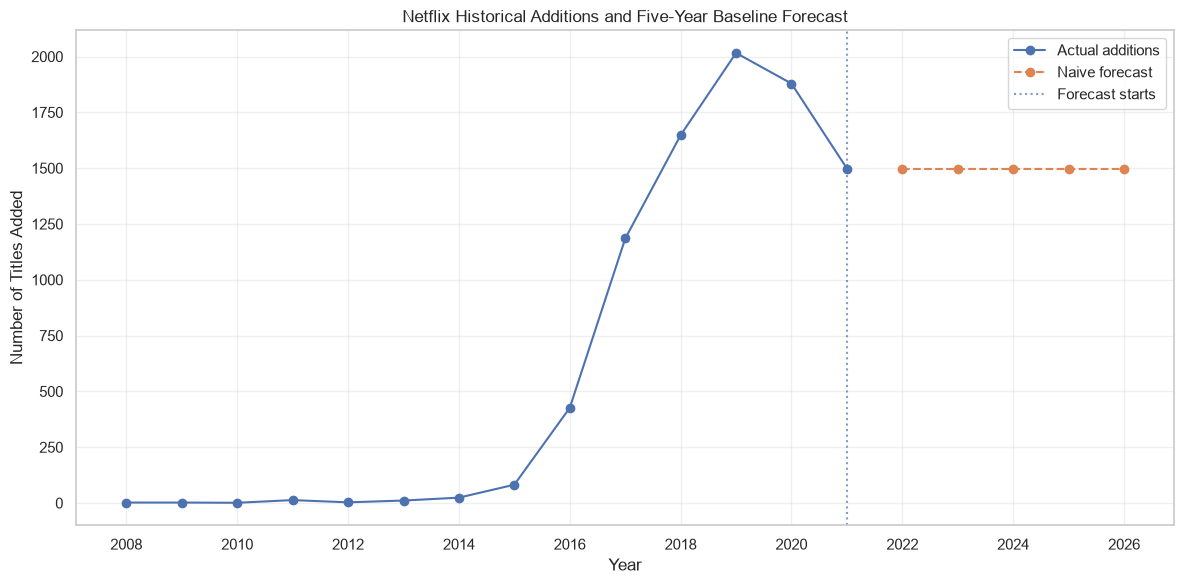

In [26]:
# Plot observed additions and the five-year baseline forecast.
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    series.index, series.values,
    marker="o", label="Actual additions"
)

ax.plot(
    forecast.index, forecast.values,
    marker="o", linestyle="--", label="Naive forecast"
)

ax.axvline(
    series.index.max(),
    linestyle=":", alpha=0.7, label="Forecast starts"
)

ax.set_title("Netflix Historical Additions and Five-Year Baseline Forecast")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Titles Added")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig("netflix_content_additions_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

### Forecast Future Content Additions

The Naive Baseline was selected because it achieved lower MAE and RMSE than Exponential Smoothing on the 2019–2021 test period. Using the last observed value of 1,498 titles added in 2021, the baseline projects the same annual count for 2022–2026.

These projections provide a reference scenario rather than a reliable estimate of future growth. The dataset ends in 2021, so the forecast does not represent verified Netflix additions after that year.


### Comparing Actual vs. Predicted Additions

This figure compares actual yearly additions with both models' predictions on the held-out test period. It helps identify which model tracked the observed decline more closely.


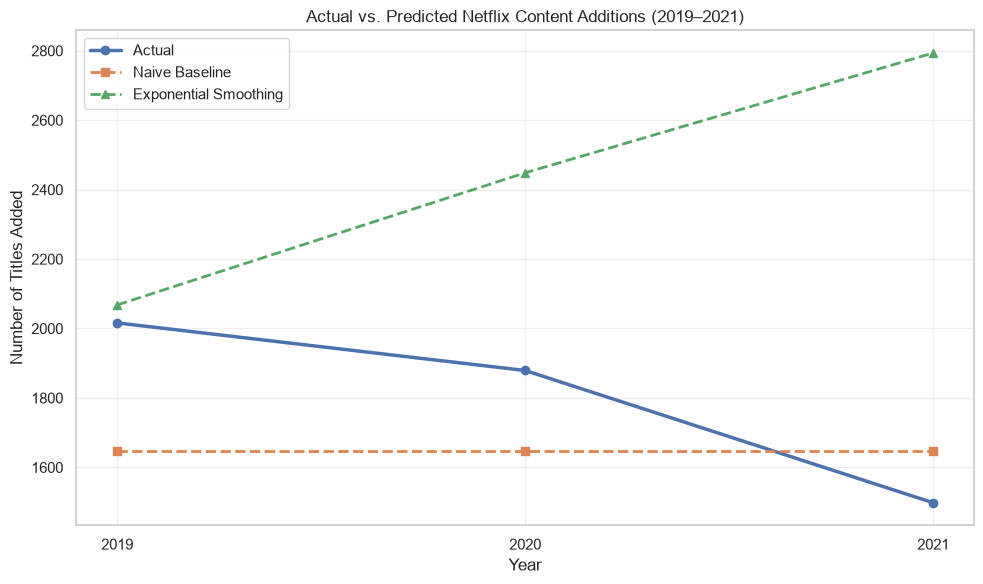

In [27]:
# Compare actual additions with both models over the test period.
fig, ax = plt.subplots(figsize=(10, 6))

years = test.index.year

ax.plot(
    years, test.values,
    marker="o", linewidth=2.5, label="Actual"
)

ax.plot(
    years, naive_predictions,
    marker="s", linestyle="--", linewidth=2, label="Naive Baseline"
)

ax.plot(
    years, smoothing_predictions.values,
    marker="^", linestyle="--", linewidth=2, label="Exponential Smoothing"
)

ax.set_title("Actual vs. Predicted Netflix Content Additions (2019–2021)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Titles Added")
ax.set_xticks(years)
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig("netflix_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

### Final Model Comparison

The evaluation showed that the Naive Baseline outperformed Exponential Smoothing on the three-year test period.

* **Naive Baseline:** MAE of 249.67 and RMSE of 265.38.
* **Exponential Smoothing:** MAE of 638.93 and RMSE of 817.60.

The Naive Baseline produced smaller prediction errors because it maintained a constant forecast, while Exponential Smoothing projected continued growth despite the observed decline in additions after 2019.

The results demonstrate the importance of evaluating forecasting models against a simple benchmark. However, the small dataset and short test period limit the reliability of this comparison. The Naive Baseline is the preferred model for this exercise, but further validation with more recent and complete data would be necessary before using it for business planning.


## Task Machine Learning Classification

### Step 1: Feature Selection and Preparation

The goal is to classify Netflix titles as Movies or TV Shows using available metadata. We will inspect the dataset, select suitable features, and prepare the target variable before training the models.
